<a href="https://colab.research.google.com/github/Mz72100/GAN-analysis/blob/main/h1n1_hackathon_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RMDS Hackathon · Dataset B
## Who will accept an H1N1 vaccine, and who should the town send one to?

**The problem.** Everyone in town will catch the flu. A vaccine costs **\$500** and a
hospital stay costs **\$25,000**. Vaccines are posted to people's homes and are wasted if
not used, and anyone who wanted a vaccine but did not get one must be paid \$500.
We therefore need to predict, person by person, who will accept a vaccine
(`h1n1_vaccine`), in the way that makes the town's total bill as small as possible.

**Our approach in one line.** Train several models to estimate each person's chance of
accepting, then send a vaccine only when the expected hospital saving outweighs the
risk of wasting \$500.

| Section | What happens |
|---|---|
| 1. Setup | Libraries, settings, loading the data |
| 2. Data exploration | What the data looks like and what relates to vaccination |
| 3. Pre-processing | Handling missing answers and text columns |
| 4. Cost model | Turning a prediction into dollars |
| 5. Modelling | Eight candidate models, cross-validated |
| 6. Performance analysis | Standard metrics, then cost |
| 7. Submission files | The five best models |
| 8. Explainable AI | What drives the predictions |
| 9. Final answer | Which model saves the most money |
| 10. Summary and references | Key points, limitations, sources |

**How to run:** set `GROUP` in the first code cell, choose *Runtime → Run all*, and pick
the training and testing CSV files when the **Choose Files** button appears.

---
## 1. Setup
All settings live in this one cell, so nothing further down needs editing.

In [1]:
# --- Libraries ---
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score,
                             precision_score, recall_score, confusion_matrix)
from sklearn.inspection import permutation_importance

try:
    from IPython.display import display      # nice tables in Colab / Jupyter
except ImportError:
    display = print

# --- General settings ---
GROUP = 0                      # your group number (used in the submission file names)
TARGET = "h1n1_vaccine"        # what we predict: 1 = accepts the vaccine
ID = "respondent_id"           # identifier, never used as a feature
SEED = 42                      # makes every run give the same result

# --- Prices from the assignment sheet ---
VACCINE_COST = 500
HOSP_COST = 25_000

# --- Hospitalisation assumptions (sources in section 4) ---
AVG_P_HOSP = 0.0045                        # average risk for an infected, unvaccinated person
VE_UNDER_65 = 0.62                         # vaccine effectiveness, under 65
VE_65_PLUS = 0.43                          # vaccine effectiveness, 65+
CHRONIC_MULT = {0: 1, 1: 4, 2: 9, 3: 20}   # relative risk by number of chronic conditions (3 = 3+)
AGE_65_MULT = 2.0                          # 65+ have double the risk

# --- Chart style ---
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#b5b4ae", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})


def headline(ax, title, subtitle=None):
    """Bold takeaway title with an optional smaller explanation underneath."""
    ax.set_title(title, pad=24 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=INK, va="bottom")


def finish(filename):
    """Tidy the current chart, save it for the presentation and show it."""
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()


def money(value):
    """Format a number as dollars, e.g. $1,430,282."""
    return f"${value:,.0f}"

### Load the data
In Colab a **Choose Files** button appears: select the training and testing CSVs
together. The code works out which is which from the file names.

In [2]:
def choose_files():
    """Open a file chooser in Colab; elsewhere use the CSV files in the current folder."""
    try:
        from google.colab import files
        print("Choose the training and testing CSV files (select both)")
        names = list(files.upload())
    except ImportError:
        names = glob.glob("*.csv")
    names = [n for n in names if "submission" not in n.lower()]
    train_file = next(n for n in names if "train" in n.lower())
    test_file = next(n for n in names if "test" in n.lower())
    return train_file, test_file


train_file, test_file = choose_files()
train = pd.read_csv(train_file)     # has the answer column h1n1_vaccine
test = pd.read_csv(test_file)       # no answer column: this is what we predict

print(f"Training file: {train_file}  ->  {train.shape[0]:,} people, {train.shape[1]} columns")
print(f"Testing file:  {test_file}  ->  {test.shape[0]:,} people, {test.shape[1]} columns")
display(train.head())

Choose the training and testing CSV files (select both)


Saving dataset_B_testing.csv to dataset_B_testing (1).csv
Saving dataset_B_training.csv to dataset_B_training (1).csv
Training file: dataset_B_training (1).csv  ->  4,756 people, 31 columns
Testing file:  dataset_B_testing (1).csv  ->  4,749 people, 30 columns


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0


---
## 2. Data exploration
Before modelling we check three things: how balanced the target is, where answers are
missing, and which survey answers go together with getting vaccinated.

In [3]:
# Column types, non-missing counts and basic statistics
train.info()
display(train.describe().T.round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker                  4625 non-null   f

,count,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,2378.50,1373.08,1.0,1189.75,2378.5,3567.25,4756.0
h1n1_concern,4741.0,1.66,0.89,0.0,1.00,2.0,2.00,3.0
h1n1_knowledge,4734.0,1.31,0.61,0.0,1.00,1.0,2.00,2.0
behavioral_antiviral_meds,4739.0,0.06,0.23,0.0,0.00,0.0,0.00,1.0
behavioral_avoidance,4729.0,0.74,0.44,0.0,0.00,1.0,1.00,1.0
behavioral_face_mask,4752.0,0.08,0.27,0.0,0.00,0.0,0.00,1.0
behavioral_wash_hands,4748.0,0.84,0.36,0.0,1.00,1.0,1.00,1.0
behavioral_large_gatherings,4747.0,0.36,0.48,0.0,0.00,0.0,1.00,1.0
behavioral_outside_home,4741.0,0.34,0.47,0.0,0.00,0.0,1.00,1.0
behavioral_touch_face,4736.0,0.70,0.46,0.0,0.00,1.0,1.00,1.0


### 2.1 Target balance and missing answers

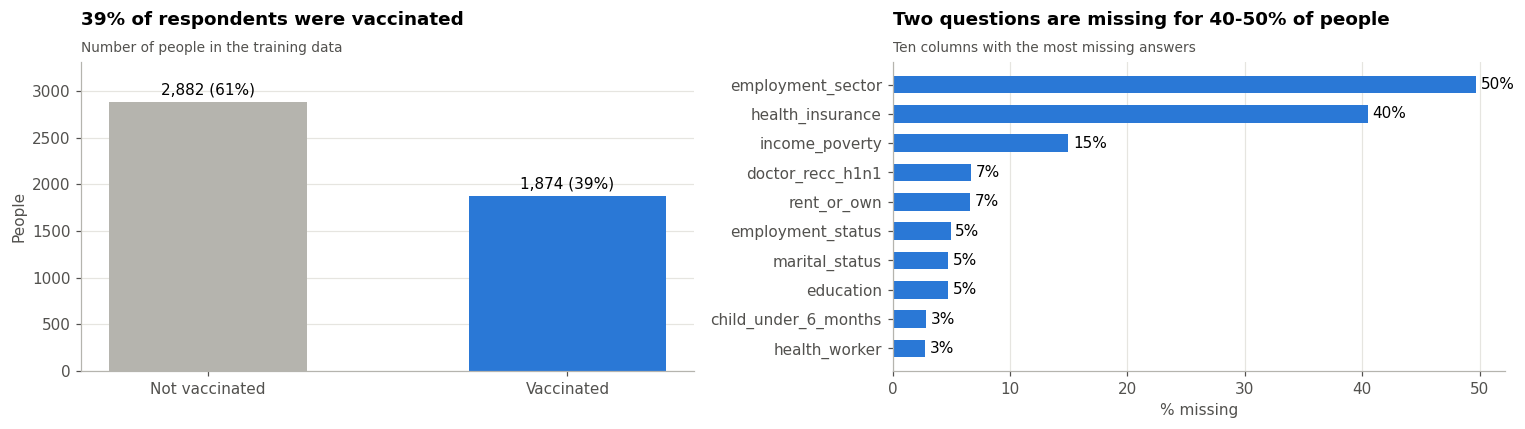

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: how many people did / did not get vaccinated
counts = train[TARGET].value_counts().rename({0: "Not vaccinated", 1: "Vaccinated"})
bars = axes[0].bar(counts.index, counts.values, color=[GREY, BLUE], width=0.55)
axes[0].bar_label(bars, labels=[f"{v:,} ({v / len(train):.0%})" for v in counts.values], padding=3)
headline(axes[0], f"{train[TARGET].mean():.0%} of respondents were vaccinated",
         "Number of people in the training data")
axes[0].set_ylabel("People")
axes[0].set_ylim(0, counts.max() * 1.15)
axes[0].grid(False, axis="x")

# Right: the ten columns with the most missing answers
missing = (train.isna().mean() * 100).sort_values().tail(10)
bars = axes[1].barh(missing.index, missing.values, color=BLUE, height=0.6)
axes[1].bar_label(bars, fmt="%.0f%%", padding=3)
headline(axes[1], "Two questions are missing for 40-50% of people",
         "Ten columns with the most missing answers")
axes[1].set_xlabel("% missing")
axes[1].grid(False, axis="y")

finish("eda_balance_missing.png")

### 2.2 Vaccination rate by answer
Each chart shows the share of people vaccinated for every answer to one question.
Big differences between bars mean the question is useful for prediction.

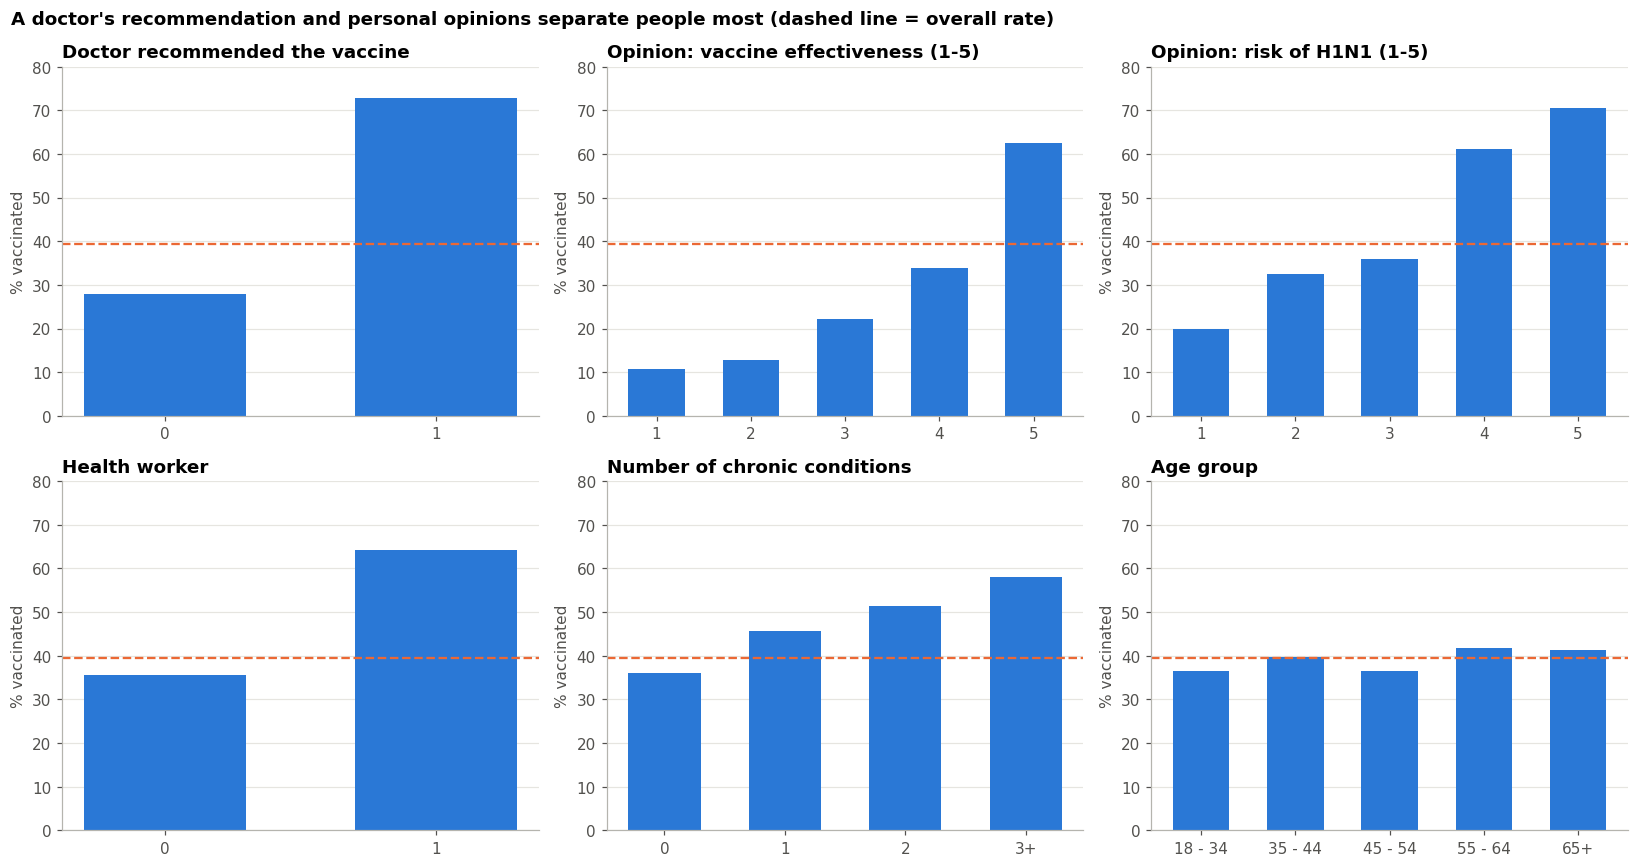

In [5]:
key_features = {
    "doctor_recc_h1n1": "Doctor recommended the vaccine",
    "opinion_h1n1_vacc_effective": "Opinion: vaccine effectiveness (1-5)",
    "opinion_h1n1_risk": "Opinion: risk of H1N1 (1-5)",
    "health_worker": "Health worker",
    "number_chronic_med_conditions": "Number of chronic conditions",
    "age_group": "Age group",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.ravel(), key_features.items()):
    groups = train[col]
    if col == "number_chronic_med_conditions":      # very few people have more than 3
        groups = groups.clip(upper=3).replace({3: "3+"}).astype(str)
    rate = train.groupby(groups)[TARGET].mean() * 100
    labels = [str(v).replace(".0", "").replace(" Years", "") for v in rate.index]
    ax.bar(labels, rate.values, color=BLUE, width=0.6)
    ax.axhline(train[TARGET].mean() * 100, color=ORANGE, linestyle="--", linewidth=1.5)  # overall rate
    ax.set_title(title)
    ax.set_ylabel("% vaccinated")
    ax.set_ylim(0, 80)                      # same scale on every panel, so bars are comparable
    ax.grid(False, axis="x")
fig.suptitle("A doctor's recommendation and personal opinions separate people most "
             "(dashed line = overall rate)", fontweight="bold", x=0.01, ha="left")
finish("eda_vaccination_rates.png")

### 2.3 Correlation with the target

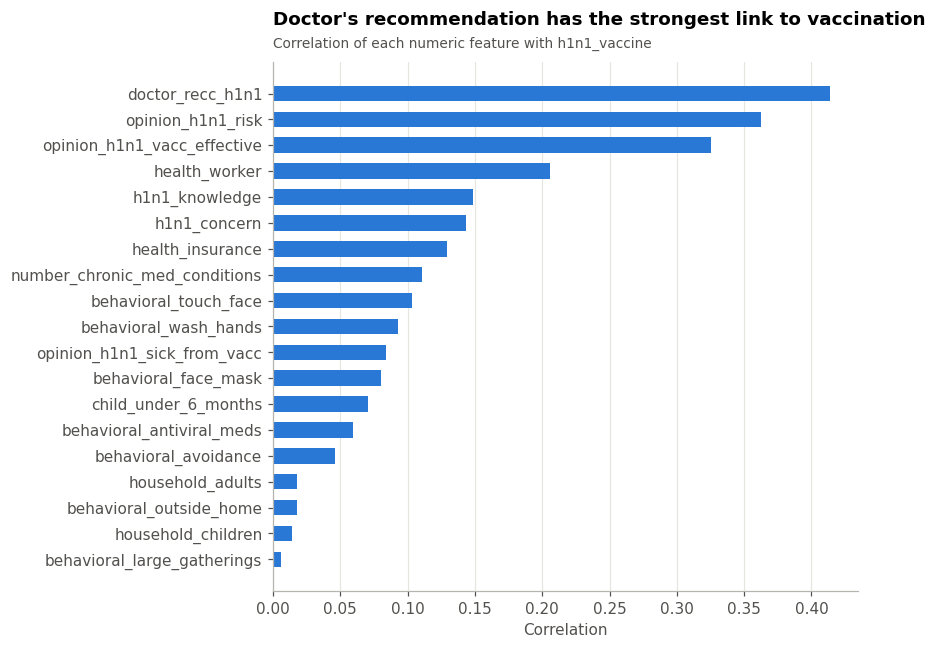

In [6]:
corr = train.drop(columns=ID).corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr.index, corr.values, color=np.where(corr > 0, BLUE, ORANGE), height=0.6)
headline(ax, "Doctor's recommendation has the strongest link to vaccination",
         "Correlation of each numeric feature with h1n1_vaccine")
ax.set_xlabel("Correlation")
ax.grid(False, axis="y")
finish("eda_correlations.png")

### What the exploration shows
* **Balanced enough.** About 39% of respondents were vaccinated, so no re-sampling is needed.
* **Strongest signals.** A doctor's recommendation, believing the vaccine works and
  feeling at risk. Health workers are also far more likely to be vaccinated.
* **Missing answers.** `employment_sector` (about 50%) and `health_insurance` (about 40%)
  have many gaps. Dropping those rows would lose half the data, so instead we keep
  "did not answer" as information the models can use.

---
## 3. Pre-processing
The same steps are applied to the training and test data through one pipeline, so
nothing learned from the test set can leak into the models.

| Column type | Missing answers | Then |
|---|---|---|
| Numbers (binary, 1-5 scales, counts) | Filled with the median, plus a "was missing" flag | Rescaled |
| Text (age group, education, ...) | Become their own "missing" category | One-hot encoded |

In [7]:
# Split the predictors into text columns and number columns
features = [c for c in train.columns if c not in (ID, TARGET)]
cat_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]
num_cols = [c for c in features if c not in cat_cols]

# Recipe for number columns
numeric_prep = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

# Recipe for text columns
categorical_prep = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Apply each recipe to its own columns
preprocess = ColumnTransformer([
    ("num", numeric_prep, num_cols),
    ("cat", categorical_prep, cat_cols),
])

X = train[features]              # training inputs
y = train[TARGET].to_numpy()     # training answers
X_test = test[features]          # inputs we must predict

print(f"{len(features)} features: {len(num_cols)} numeric, {len(cat_cols)} text")

29 features: 19 numeric, 10 text


---
## 4. Cost model
The hackathon is judged on money, so we first define exactly what each decision costs.
Everyone gets infected (assignment rule), which gives four cases per person:

| We send a vaccine | They want it | Vaccine money | Hospital risk |
|---|---|---|---|
| Yes | Yes | \$500 | Reduced by the vaccine |
| Yes | No  | \$500 (vaccine ruined) | Full |
| No  | Yes | \$500 (compensation) | Full |
| No  | No  | \$0 | Full |

### Hospitalisation probability
| Input | Value | Source |
|---|---|---|
| Average risk if infected | 0.45% | CDC: about 61 million US cases and 274,000 hospitalisations in the 2009 pandemic |
| Vaccine effectiveness | 62% (43% for 65+) | Borse et al., *Emerging Infectious Diseases*, 2013 |
| Chronic conditions | 4x, 9x, 20x risk for 1, 2, 3+ conditions | Ward et al., *Emerging Infectious Diseases*, 2011 |
| Age 65+ | 2x risk | CDC surveillance (direction); the size is our assumption |

The multipliers are scaled so that the *average* person in the data has the 0.45% risk.

### Decision rule
Sending a vaccine is worth it when the expected hospital saving beats the expected waste:

$$P(\text{accept}) > \frac{500}{500 + 25000 \times \text{risk} \times \text{effectiveness}}$$

So the cut-off is **personal**: the higher someone's hospital risk, the less sure we need
to be that they will accept.

In [8]:
def risk_multiplier(df):
    """Relative hospitalisation risk from chronic conditions and age."""
    chronic = df["number_chronic_med_conditions"].clip(upper=3).map(CHRONIC_MULT)
    return chronic * np.where(df["age_group"].eq("65+ Years"), AGE_65_MULT, 1.0)


# Scale so the average person in the training data has the average risk
RISK_SCALE = AVG_P_HOSP / risk_multiplier(train).mean()


def hospitalisation_inputs(df):
    """Unvaccinated hospitalisation risk and vaccine effectiveness for each person."""
    is_65_plus = df["age_group"].eq("65+ Years")
    risk = RISK_SCALE * risk_multiplier(df)
    effectiveness = np.where(is_65_plus, VE_65_PLUS, VE_UNDER_65)
    return risk.to_numpy(), effectiveness


def total_cost(y_true, y_pred, risk, effectiveness):
    """Total dollars paid by the town for a set of decisions."""
    pays_vaccine = (y_pred == 1) | (y_true == 1)     # vaccine sent, or compensation owed
    protected = (y_pred == 1) & (y_true == 1)        # vaccine sent and actually used
    hosp_risk = risk * np.where(protected, 1 - effectiveness, 1.0)
    return float((VACCINE_COST * pays_vaccine + HOSP_COST * hosp_risk).sum())


def cost_breakdown(y_true, y_pred, risk, effectiveness):
    """Split the bill into vaccine money (incl. compensation) and expected hospital money."""
    pays_vaccine = (y_pred == 1) | (y_true == 1)
    protected = (y_pred == 1) & (y_true == 1)
    hosp_risk = risk * np.where(protected, 1 - effectiveness, 1.0)
    return float(VACCINE_COST * pays_vaccine.sum()), float(HOSP_COST * hosp_risk.sum())


def cost_optimal_decision(p_accept, risk, effectiveness):
    """Send a vaccine (1) only when the expected saving beats the expected waste."""
    threshold = VACCINE_COST / (VACCINE_COST + HOSP_COST * risk * effectiveness)
    return (p_accept > threshold).astype(int)


risk_train, ve_train = hospitalisation_inputs(train)
risk_test, ve_test = hospitalisation_inputs(test)

### Risk and cut-off for each type of person

In [9]:
profile = pd.DataFrame({
    "Chronic conditions": train["number_chronic_med_conditions"].clip(upper=3).replace({3: "3+"}),
    "Age 65+": np.where(train["age_group"].eq("65+ Years"), "Yes", "No"),
    "risk": 100 * risk_train,
    "cutoff": VACCINE_COST / (VACCINE_COST + HOSP_COST * risk_train * ve_train),
})
profile = (profile.astype({"Chronic conditions": str})
           .groupby(["Chronic conditions", "Age 65+"])
           .agg(People=("risk", "size"), risk=("risk", "first"), cutoff=("cutoff", "first"))
           .reset_index())
table = profile.assign(**{
    "Hospital risk": profile["risk"].map("{:.2f}%".format),
    "Send if P(accept) is above": profile["cutoff"].map("{:.2f}".format),
}).drop(columns=["risk", "cutoff"])
display(table.set_index(["Chronic conditions", "Age 65+"]))

People Hospital risk Send if P(accept) is above
Chronic conditions Age 65+                                                 
0                  No         2616         0.14%                       0.96
                   Yes         697         0.28%                       0.94
1                  No          713         0.56%                       0.85
                   Yes         401         1.12%                       0.81
2                  No          153         1.26%                       0.72
                   Yes         102         2.52%                       0.65
3+                 No           49         2.80%                       0.53
                   Yes          25         5.61%                       0.45

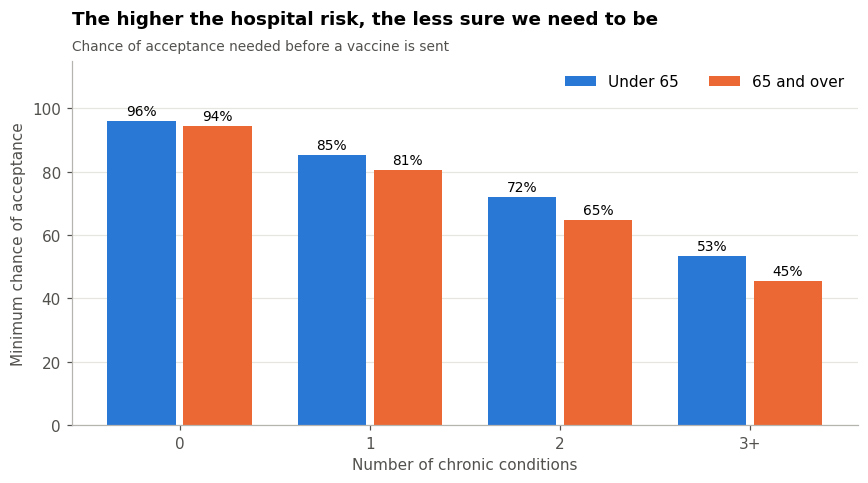

In [10]:
# The same cut-offs as a chart: how sure we must be before sending a vaccine
cutoffs = profile.pivot(index="Chronic conditions", columns="Age 65+", values="cutoff") * 100
x = np.arange(len(cutoffs))

fig, ax = plt.subplots(figsize=(8, 4.5))
for offset, (col, color, label) in zip([-0.2, 0.2], [("No", BLUE, "Under 65"), ("Yes", ORANGE, "65 and over")]):
    bars = ax.bar(x + offset, cutoffs[col], width=0.36, color=color, label=label)
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_xticks(x, cutoffs.index)
ax.set_xlabel("Number of chronic conditions")
ax.set_ylabel("Minimum chance of acceptance")
ax.set_ylim(0, 115)
ax.grid(False, axis="x")
ax.legend(loc="upper right", ncol=2)
headline(ax, "The higher the hospital risk, the less sure we need to be",
         "Chance of acceptance needed before a vaccine is sent")
finish("decision_cutoffs.png")

**Reading the table:** a healthy adult under 65 only gets a vaccine if we are about 96%
sure they will accept, because a wasted vaccine costs \$500 while the expected hospital
saving is small. For someone with three or more chronic conditions, about 50% is enough.

---
## 5. Modelling
We compare **eight separate models** from different families and submit the best five.

| Model | Idea |
|---|---|
| Logistic regression | Weighted sum of the answers |
| Linear discriminant analysis | Separates the two groups with a straight boundary |
| Decision tree | A flowchart of yes/no questions |
| K-nearest neighbours | Looks at the 50 most similar people |
| Random forest | Many trees voting |
| Extra trees | Like a random forest, with more random splits |
| Neural network | One hidden layer of 32 units |
| Gradient boosting | Trees built one after another, each fixing earlier mistakes |

**How they are scored.** 5-fold cross-validation: every person is predicted by a model
that never saw them, which imitates the test set.

**Tuning.** Settings for five of the models were picked with a grid search
(lowest cross-validated log loss); the other three use sensible defaults.

**Calibration.** The cost rule needs honest probabilities (a predicted 0.9 should mean
90%). Each model is tried with and without calibration and keeps the cheaper version.

In [11]:
models = {
    "Logistic regression": LogisticRegression(C=0.03, max_iter=3000),
    "Linear discriminant analysis": LinearDiscriminantAnalysis(),
    "Decision tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=SEED),
    "K-nearest neighbours": KNeighborsClassifier(n_neighbors=50, weights="distance"),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                            max_features=0.3, n_jobs=-1, random_state=SEED),
    "Extra trees": ExtraTreesClassifier(n_estimators=400, min_samples_leaf=5,
                                        max_features=0.3, n_jobs=-1, random_state=SEED),
    "Neural network": MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=500,
                                    early_stopping=True, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.03, max_iter=300,
                                                        max_leaf_nodes=15, l2_regularization=5.0,
                                                        random_state=SEED),
}

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_prob = {}      # cross-validated P(accept) on the training set
test_prob = {}    # P(accept) on the test set
training_log = []


def cost_of(prob):
    """Total training-set cost when decisions follow the cost rule."""
    return total_cost(y, cost_optimal_decision(prob, risk_train, ve_train), risk_train, ve_train)


for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    calibrated = CalibratedClassifierCV(pipe, method="isotonic", cv=5)

    # Cross-validated probabilities, with and without calibration
    raw_prob = cross_val_predict(pipe, X, y, cv=folds, method="predict_proba")[:, 1]
    cal_prob = cross_val_predict(calibrated, X, y, cv=folds, method="predict_proba")[:, 1]

    # Keep the cheaper version and use it for the test set
    use_calibrated = cost_of(cal_prob) < cost_of(raw_prob)
    cv_prob[name] = cal_prob if use_calibrated else raw_prob
    final_model = (calibrated if use_calibrated else pipe).fit(X, y)
    test_prob[name] = final_model.predict_proba(X_test)[:, 1]

    # Plain fitted model, used later for explainability
    models[name] = pipe.fit(X, y)

    training_log.append({"Model": name,
                         "Cost, raw": money(cost_of(raw_prob)),
                         "Cost, calibrated": money(cost_of(cal_prob)),
                         "Version used": "calibrated" if use_calibrated else "raw"})
    print(f"done: {name}")

# Average of all models, kept as a comparison only (not submitted)
cv_prob["Average of all models"] = np.mean([cv_prob[m] for m in models], axis=0)
test_prob["Average of all models"] = np.mean([test_prob[m] for m in models], axis=0)

display(pd.DataFrame(training_log).set_index("Model"))

done: Logistic regression
done: Linear discriminant analysis
done: Decision tree
done: K-nearest neighbours
done: Random forest
done: Extra trees
done: Neural network
done: Gradient boosting


,"Cost, raw","Cost, calibrated",Version used
Model,,,
Logistic regression,"$1,438,834","$1,436,231",calibrated
Linear discriminant analysis,"$1,435,795","$1,436,235",raw
Decision tree,"$1,441,880","$1,444,917",raw
K-nearest neighbours,"$1,448,047","$1,441,255",calibrated
Random forest,"$1,432,412","$1,433,068",raw
Extra trees,"$1,433,427","$1,433,655",raw
Neural network,"$1,439,837","$1,437,194",calibrated
Gradient boosting,"$1,430,282","$1,431,888",raw


---
## 6. Performance analysis
First the standard classification metrics, then the metric that matters here: money.

### 6.1 Standard metrics (at the usual 0.5 cut-off)
* **AUC**: how well the model ranks people (1.0 = perfect, 0.5 = random).
* **Accuracy**: share of people classified correctly.
* **Precision**: of those predicted to accept, how many really do.
* **Recall**: of those who accept, how many we find.

In [12]:
metrics = pd.DataFrame({
    name: {
        "AUC": roc_auc_score(y, p),
        "Accuracy": accuracy_score(y, p > 0.5),
        "Precision": precision_score(y, p > 0.5),
        "Recall": recall_score(y, p > 0.5),
    } for name, p in cv_prob.items()
}).T.sort_values("AUC", ascending=False).round(3)
display(metrics)

,AUC,Accuracy,Precision,Recall
Average of all models,0.856,0.787,0.769,0.656
Gradient boosting,0.854,0.786,0.759,0.670
Random forest,0.851,0.784,0.766,0.649
Linear discriminant analysis,0.849,0.787,0.762,0.667
Extra trees,0.848,0.779,0.755,0.650
Logistic regression,0.848,0.786,0.763,0.661
Neural network,0.846,0.783,0.770,0.641
K-nearest neighbours,0.832,0.769,0.759,0.606
Decision tree,0.823,0.764,0.716,0.666


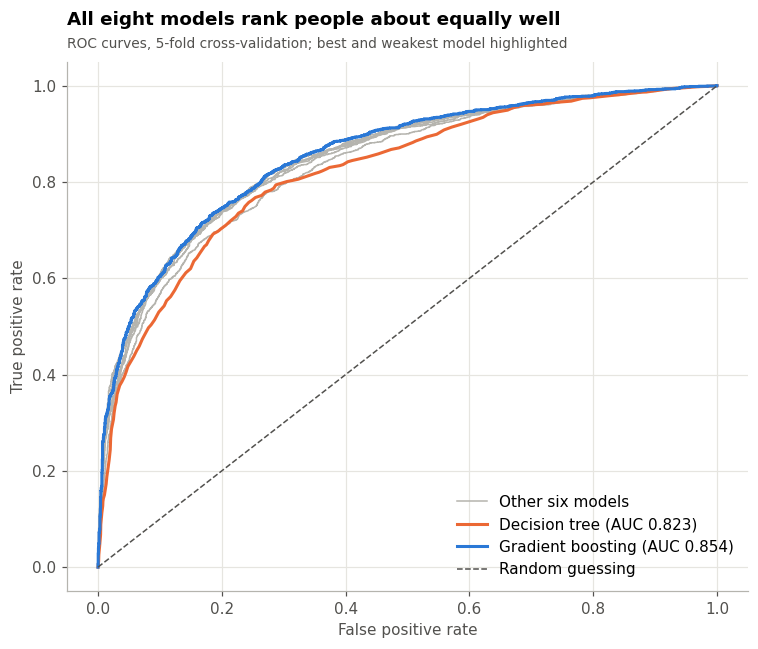

In [13]:
# ROC curves: the closer a curve is to the top-left corner, the better
single = [m for m in metrics.index if m in models]     # the eight separate models
top_model, weakest_model = single[0], single[-1]

fig, ax = plt.subplots(figsize=(7, 6))
for name in single[1:-1]:                              # the middle of the pack, in grey
    fpr, tpr, _ = roc_curve(y, cv_prob[name])
    ax.plot(fpr, tpr, color=GREY, linewidth=1)
ax.plot([], [], color=GREY, linewidth=1, label="Other six models")
for name, color in [(weakest_model, ORANGE), (top_model, BLUE)]:
    fpr, tpr, _ = roc_curve(y, cv_prob[name])
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{name} (AUC {metrics.loc[name, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=INK, linestyle="--", linewidth=1, label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
headline(ax, "All eight models rank people about equally well",
         "ROC curves, 5-fold cross-validation; best and weakest model highlighted")
finish("roc_curves.png")

### 6.2 Total cost
Each model's probabilities are turned into decisions with the cost rule and priced.
For context we add three reference points:
* **Send to nobody**: no model needed, pay compensation to everyone who wanted one.
* **Send to everybody**: waste a vaccine on everyone who refuses.
* **Perfect knowledge**: the unreachable best case.

We also price the usual 0.5 cut-off to show why the cost rule matters.

In [14]:
def decide(prob, rule, risk, effectiveness):
    """Turn probabilities into send / don't send decisions."""
    if rule == "cost":
        return cost_optimal_decision(prob, risk, effectiveness)
    return (prob > rule).astype(int)


# A strategy = a model + a rule for turning probabilities into decisions
strategies = {name: (name, "cost") for name in cv_prob}
strategies["Average of all models, 0.5 cut-off"] = ("Average of all models", 0.5)

rows = []
for label, (name, rule) in strategies.items():
    pred = decide(cv_prob[name], rule, risk_train, ve_train)
    rows.append({"strategy": label,
                 "cost": total_cost(y, pred, risk_train, ve_train),
                 "vaccines_sent": int(pred.sum())})
results = pd.DataFrame(rows).sort_values("cost").reset_index(drop=True)

references = {
    "Send to nobody": total_cost(y, np.zeros_like(y), risk_train, ve_train),
    "Send to everybody": total_cost(y, np.ones_like(y), risk_train, ve_train),
    "Perfect knowledge": total_cost(y, y, risk_train, ve_train),
}

display(pd.DataFrame({
    "Strategy": results["strategy"],
    "Total cost": results["cost"].map(money),
    "Cost per person": (results["cost"] / len(y)).map("${:,.2f}".format),
    "Vaccines sent": results["vaccines_sent"],
}).set_index("Strategy"))
print("Reference points:", {k: money(v) for k, v in references.items()})

,Total cost,Cost per person,Vaccines sent
Strategy,,,
Gradient boosting,"$1,430,282",$300.73,378
Random forest,"$1,432,412",$301.18,313
Extra trees,"$1,433,427",$301.39,344
Average of all models,"$1,435,029",$301.73,330
Linear discriminant analysis,"$1,435,795",$301.89,451
Logistic regression,"$1,436,231",$301.98,426
Neural network,"$1,437,194",$302.19,429
K-nearest neighbours,"$1,441,255",$303.04,371
Decision tree,"$1,441,880",$303.17,400


Reference points: {'Send to nobody': '$1,472,050', 'Send to everybody': '$2,784,233', 'Perfect knowledge': '$1,343,233'}


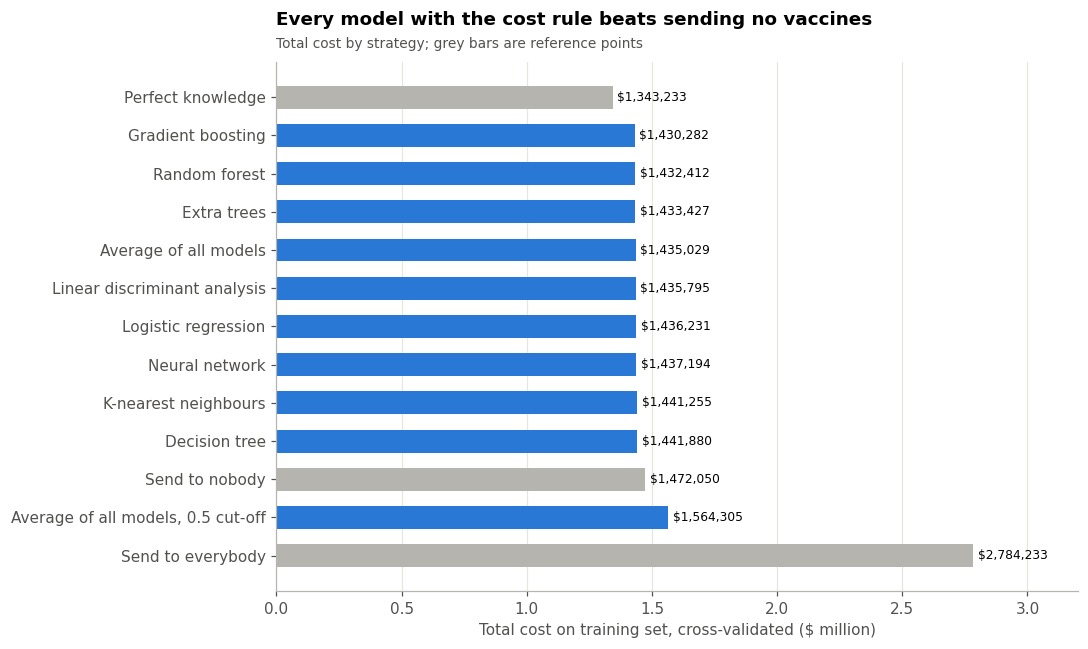

In [15]:
# All strategies and reference points on one chart (cheapest at the top)
all_costs = pd.Series({**references, **results.set_index("strategy")["cost"].to_dict()})
all_costs = all_costs.sort_values(ascending=False)
colors = [GREY if label in references else BLUE for label in all_costs.index]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(all_costs.index, all_costs.values / 1e6, color=colors, height=0.6)
ax.bar_label(bars, labels=[money(v) for v in all_costs.values], padding=3, fontsize=8)
ax.set_xlabel("Total cost on training set, cross-validated ($ million)")
ax.set_xlim(0, all_costs.max() / 1e6 * 1.15)
ax.grid(False, axis="y")
headline(ax, "Every model with the cost rule beats sending no vaccines",
         "Total cost by strategy; grey bars are reference points")
finish("cost_comparison.png")

### 6.3 Where the money goes
The bill has two parts: vaccine money (vaccines sent plus compensation) and expected
hospital money. The best model is compared with the three reference points.

Best strategy: Gradient boosting


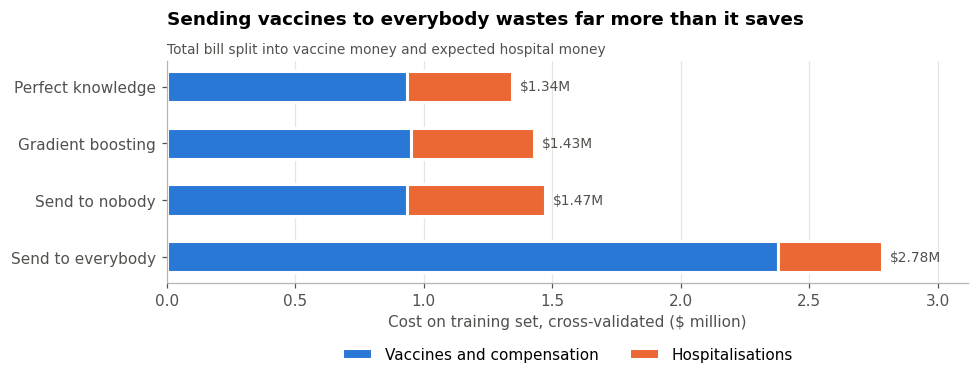

In [16]:
best_label = results.loc[0, "strategy"]
best_model, best_rule = strategies[best_label]
best_pred = decide(cv_prob[best_model], best_rule, risk_train, ve_train)
print("Best strategy:", best_label)

scenarios = {
    "Perfect knowledge": y,
    best_label: best_pred,
    "Send to nobody": np.zeros_like(y),
    "Send to everybody": np.ones_like(y),
}
parts = pd.DataFrame({k: cost_breakdown(y, v, risk_train, ve_train) for k, v in scenarios.items()},
                     index=["Vaccines and compensation", "Hospitalisations"]).T / 1e6
parts = parts.iloc[::-1]                                   # cheapest at the top

fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(parts))
for col, color in zip(parts.columns, [BLUE, ORANGE]):
    ax.barh(parts.index, parts[col], left=left, color=color, height=0.55,
            label=col, edgecolor="white", linewidth=2)
    left += parts[col].to_numpy()
for i, total in enumerate(left):
    ax.text(total + 0.03, i, f"${total:.2f}M", va="center", fontsize=9, color=INK)
ax.set_xlabel("Cost on training set, cross-validated ($ million)")
ax.set_xlim(0, left.max() * 1.12)
ax.grid(False, axis="y")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=2)
headline(ax, "Sending vaccines to everybody wastes far more than it saves",
         "Total bill split into vaccine money and expected hospital money")
finish("cost_breakdown.png")

### 6.4 Where the best model is right and wrong

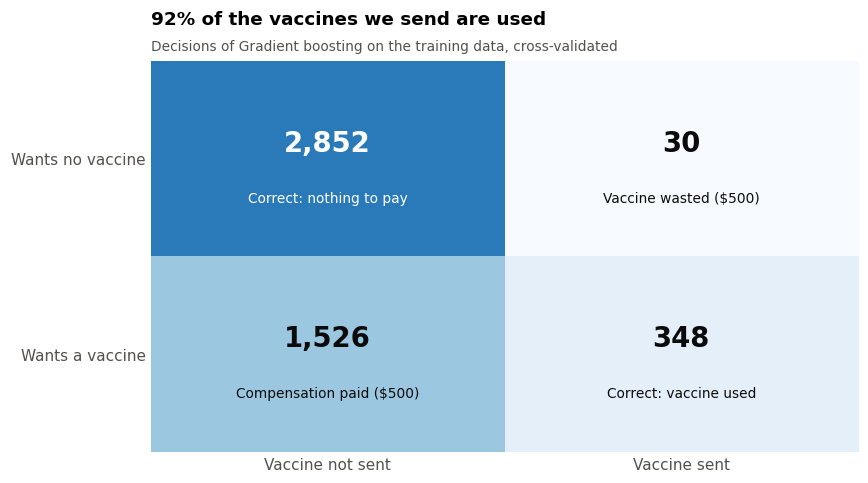

In [17]:
matrix = confusion_matrix(y, best_pred)
row_labels = ["Wants no vaccine", "Wants a vaccine"]
col_labels = ["Vaccine not sent", "Vaccine sent"]
meaning = [["Correct: nothing to pay", "Vaccine wasted ($500)"],
           ["Compensation paid ($500)", "Correct: vaccine used"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.4, aspect="auto")
for i in range(2):
    for j in range(2):
        color = "white" if matrix[i, j] > matrix.max() * 0.6 else "#0b0b0b"
        ax.text(j, i - 0.08, f"{matrix[i, j]:,}", ha="center", va="center",
                fontsize=18, fontweight="bold", color=color)
        ax.text(j, i + 0.2, meaning[i][j], ha="center", va="center", fontsize=9, color=color)
ax.set_xticks([0, 1], col_labels)
ax.set_yticks([0, 1], row_labels)
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
headline(ax, f"{matrix[1, 1] / matrix[:, 1].sum():.0%} of the vaccines we send are used",
         f"Decisions of {best_model} on the training data, cross-validated")
finish("confusion_matrix.png")

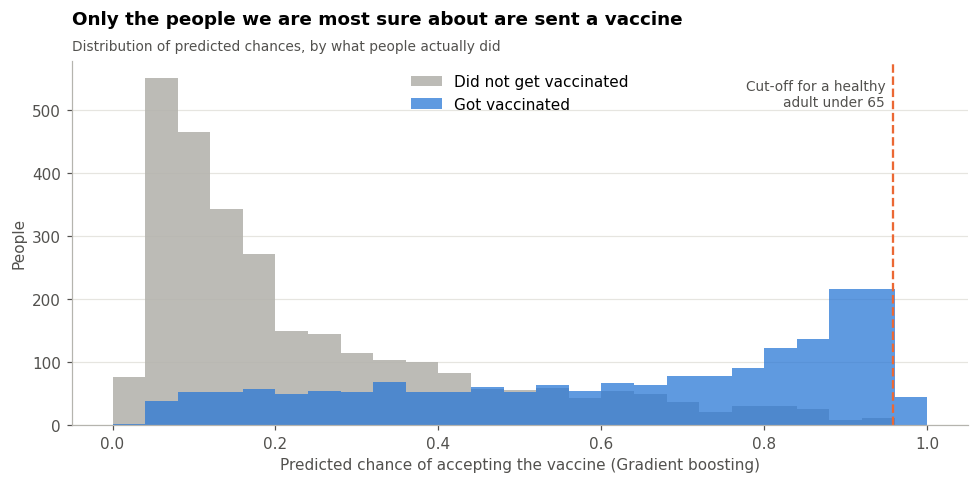

In [18]:
# Predicted chance of acceptance, split by what people actually did
healthy_cutoff = profile["cutoff"].max()
bins = np.linspace(0, 1, 26)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(cv_prob[best_model][y == 0], bins=bins, color=GREY, alpha=0.9, label="Did not get vaccinated")
ax.hist(cv_prob[best_model][y == 1], bins=bins, color=BLUE, alpha=0.75, label="Got vaccinated")
ax.axvline(healthy_cutoff, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(healthy_cutoff - 0.01, ax.get_ylim()[1] * 0.95, "Cut-off for a healthy\nadult under 65",
        ha="right", va="top", fontsize=9, color=INK)
ax.set_xlabel(f"Predicted chance of accepting the vaccine ({best_model})")
ax.set_ylabel("People")
ax.grid(False, axis="x")
ax.legend(loc="upper center")
headline(ax, "Only the people we are most sure about are sent a vaccine",
         "Distribution of predicted chances, by what people actually did")
finish("probability_distribution.png")

**Reading the charts:** the model sends few vaccines, but almost all of them are used
(top-right box is small). Many people who wanted a vaccine are not sent one
(bottom-left): that is deliberate, because for low-risk people paying compensation is
cheaper than gambling on a wasted vaccine. The histogram shows the same thing: only the
far right of the distribution clears the cut-off.

### 6.5 Sensitivity check
Our hospitalisation risk is an estimate. Does the model still beat "send to nobody" if
the true average risk is half, double or four times our figure?

,Best model,Send to nobody,Saving,Vaccines sent
Average risk,,,,
0.22%,"$1,191,606","$1,204,525","$12,919",218
0.45%,"$1,430,282","$1,472,050","$41,768",378
0.90%,"$1,903,652","$2,007,100","$103,448",641
1.80%,"$2,820,919","$3,077,200","$256,281",985


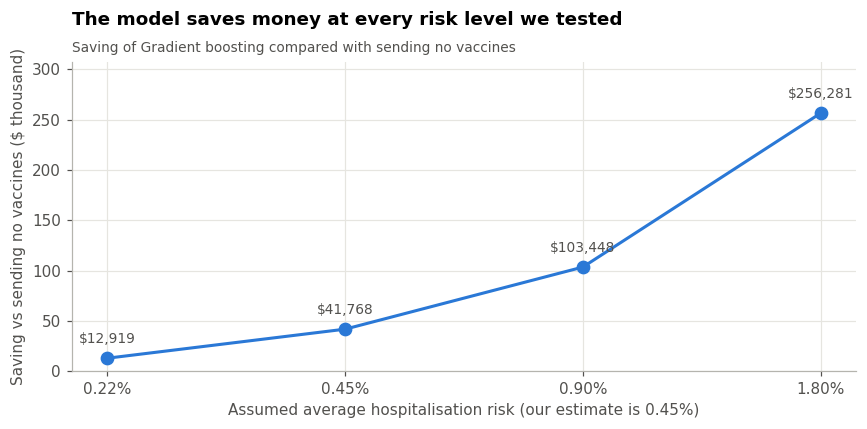

In [19]:
sensitivity = []
for factor in [0.5, 1.0, 2.0, 4.0]:
    risk = risk_train * factor
    pred = decide(cv_prob[best_model], best_rule, risk, ve_train)
    model_cost = total_cost(y, pred, risk, ve_train)
    nobody_cost = total_cost(y, np.zeros_like(y), risk, ve_train)
    sensitivity.append({
        "Average risk": f"{AVG_P_HOSP * factor:.2%}",
        "Best model": model_cost,
        "Send to nobody": nobody_cost,
        "Saving": nobody_cost - model_cost,
        "Vaccines sent": int(pred.sum()),
    })
sensitivity = pd.DataFrame(sensitivity).set_index("Average risk")
display(sensitivity.assign(**{c: sensitivity[c].map(money)
                              for c in ["Best model", "Send to nobody", "Saving"]}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sensitivity.index, sensitivity["Saving"] / 1e3, color=BLUE, linewidth=2, marker="o", markersize=8)
for label, value in sensitivity["Saving"].items():
    ax.annotate(money(value), (label, value / 1e3), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=9, color=INK)
ax.set_xlabel("Assumed average hospitalisation risk (our estimate is 0.45%)")
ax.set_ylabel("Saving vs sending no vaccines ($ thousand)")
ax.set_ylim(0, sensitivity["Saving"].max() / 1e3 * 1.2)
headline(ax, "The model saves money at every risk level we tested",
         f"Saving of {best_model} compared with sending no vaccines")
finish("sensitivity.png")

**Result:** the model saves money in every scenario, and the saving grows quickly as
the risk rises, because more vaccines become worth sending.

---
## 7. Submission files
The **five cheapest separate models** are written in the same format as
`dataset_B_example_submission.csv`: two columns, `respondent_id` and `h1n1_vaccine`
(1.0 = send a vaccine, 0.0 = do not). File names follow the rules:
`challenge_submission_group_X_order_Y.csv`, where order 1 is our best result.

In [20]:
# Single models only, cheapest first (the average and the 0.5 cut-off are comparisons)
model_ranking = [s for s in results["strategy"] if s in models]

submitted = []
for rank, name in enumerate(model_ranking[:5], start=1):
    pred = decide(test_prob[name], "cost", risk_test, ve_test)
    filename = f"challenge_submission_group_{GROUP}_order_{rank}.csv"
    pd.DataFrame({ID: test[ID], TARGET: pred.astype(float)}).to_csv(filename, index=False)
    submitted.append({"File": filename, "Model": name,
                      "Vaccines sent": f"{pred.sum():,} of {len(pred):,}"})
display(pd.DataFrame(submitted).set_index("File"))

,Model,Vaccines sent
File,,
challenge_submission_group_0_order_1.csv,Gradient boosting,"376 of 4,749"
challenge_submission_group_0_order_2.csv,Random forest,"334 of 4,749"
challenge_submission_group_0_order_3.csv,Extra trees,"344 of 4,749"
challenge_submission_group_0_order_4.csv,Linear discriminant analysis,"459 of 4,749"
challenge_submission_group_0_order_5.csv,Logistic regression,"437 of 4,749"


---
## 8. Explainable AI
Two views of *why* the models predict what they do.

### 8.1 Which features matter most?
Permutation importance: shuffle one feature at a time and measure how much the best
model's AUC drops. A bigger drop means the model relies on that feature more.

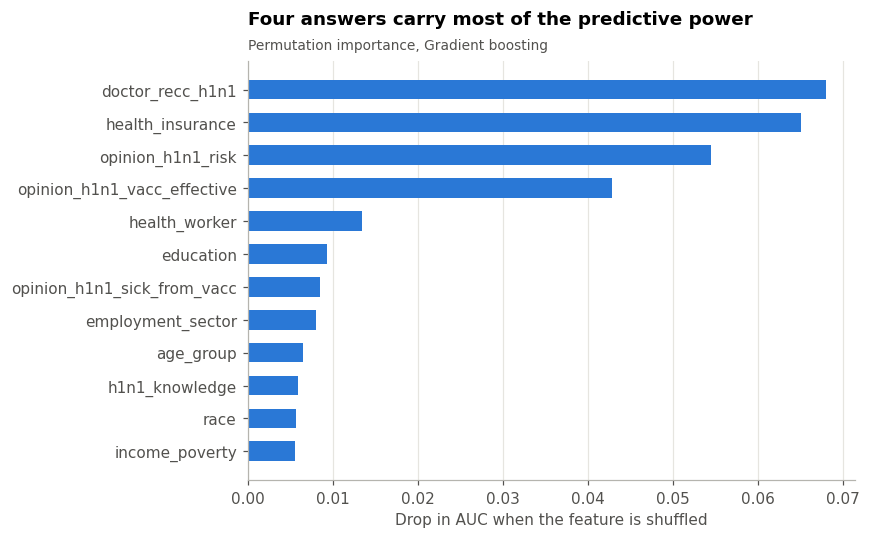

In [21]:
importance = permutation_importance(models[model_ranking[0]], X, y, scoring="roc_auc",
                                    n_repeats=5, random_state=SEED, n_jobs=-1)
top = pd.Series(importance.importances_mean, index=features).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.set_xlabel("Drop in AUC when the feature is shuffled")
ax.grid(False, axis="y")
headline(ax, "Four answers carry most of the predictive power",
         f"Permutation importance, {model_ranking[0]}")
finish("feature_importance.png")

### 8.2 In which direction does each feature push?
Logistic regression coefficients: blue bars make accepting the vaccine more likely,
red bars less likely.

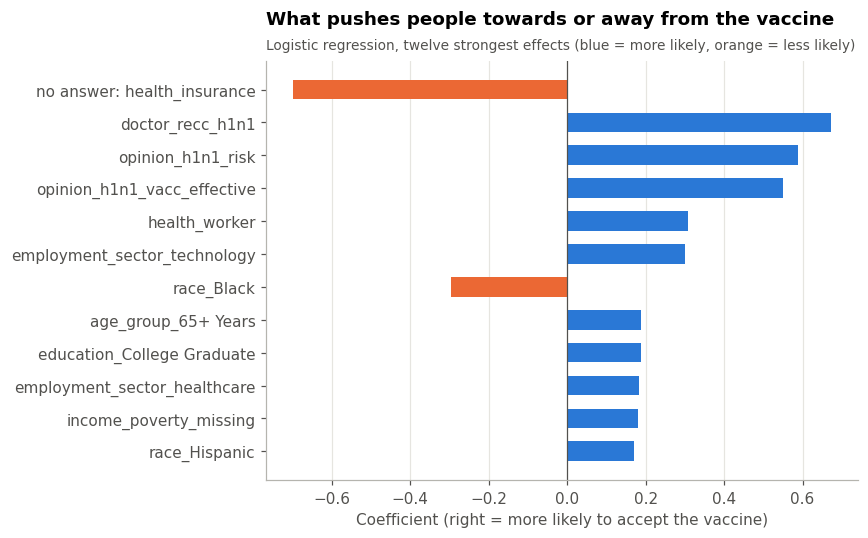

In [22]:
logit = models["Logistic regression"]
names = [n.split("__", 1)[1].replace("missingindicator_", "no answer: ")
         for n in logit["prep"].get_feature_names_out()]
coefs = pd.Series(logit["model"].coef_[0], index=names)
strongest = coefs.reindex(coefs.abs().sort_values().tail(12).index)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(strongest.index, strongest.values, color=np.where(strongest > 0, BLUE, ORANGE), height=0.6)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Coefficient (right = more likely to accept the vaccine)")
ax.grid(False, axis="y")
headline(ax, "What pushes people towards or away from the vaccine",
         "Logistic regression, twelve strongest effects (blue = more likely, orange = less likely)")
finish("logistic_coefficients.png")

**What drives the predictions:** a doctor's recommendation, health insurance (including
whether the question was answered at all), and the person's own opinion of H1N1 risk
and vaccine effectiveness. These match what the exploration in section 2 suggested.

---
## 9. Final answer: which model cuts the cost most?
Every model is compared with the simplest alternative, sending no vaccines at all.

In [23]:
baseline = references["Send to nobody"]
final = results[results["strategy"].isin(models)].reset_index(drop=True)
final["saving"] = baseline - final["cost"]

display(pd.DataFrame({
    "Rank": range(1, len(final) + 1),
    "Model": final["strategy"],
    "Total cost": final["cost"].map(money),
    "Saving vs no vaccines": final["saving"].map(money),
    "Saving %": (100 * final["saving"] / baseline).map("{:.2f}%".format),
    "Vaccines sent": final["vaccines_sent"],
    "Submitted as": [f"order_{i}" if i <= 5 else "not submitted" for i in range(1, len(final) + 1)],
}).set_index("Rank"))

winner = final.iloc[0]
print(f"BEST MODEL: {winner['strategy']}")
print(f"Total cost: {money(winner['cost'])} (${winner['cost'] / len(y):,.2f} per person)")
print(f"Saves {money(winner['saving'])} ({100 * winner['saving'] / baseline:.2f}%) "
      f"compared with sending no vaccines")

,Model,Total cost,Saving vs no vaccines,Saving %,Vaccines sent,Submitted as
Rank,,,,,,
1,Gradient boosting,"$1,430,282","$41,768",2.84%,378,order_1
2,Random forest,"$1,432,412","$39,638",2.69%,313,order_2
3,Extra trees,"$1,433,427","$38,623",2.62%,344,order_3
4,Linear discriminant analysis,"$1,435,795","$36,255",2.46%,451,order_4
5,Logistic regression,"$1,436,231","$35,819",2.43%,426,order_5
6,Neural network,"$1,437,194","$34,856",2.37%,429,not submitted
7,K-nearest neighbours,"$1,441,255","$30,795",2.09%,371,not submitted
8,Decision tree,"$1,441,880","$30,170",2.05%,400,not submitted


BEST MODEL: Gradient boosting
Total cost: $1,430,282 ($300.73 per person)
Saves $41,768 (2.84%) compared with sending no vaccines


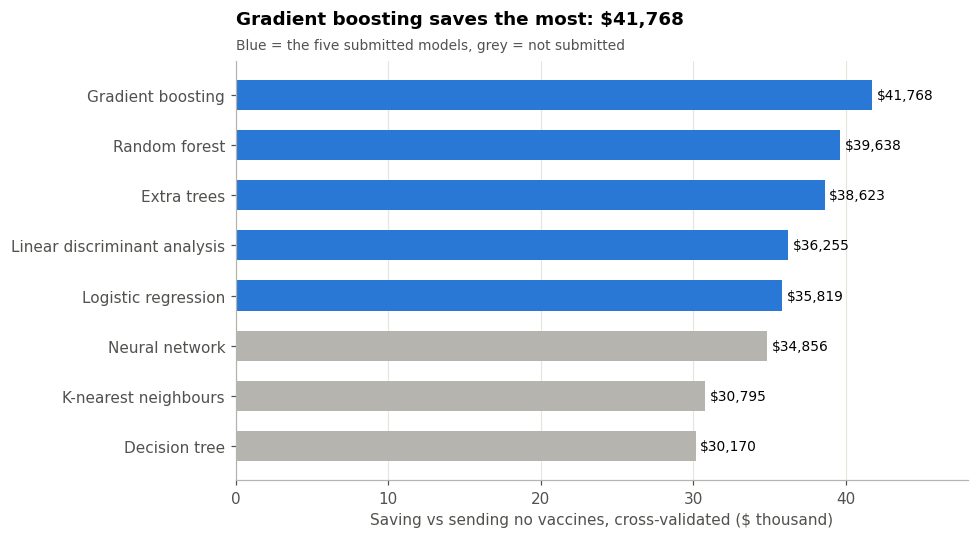

In [24]:
# Money saved by each model; the five submitted models are in blue
plot_data = final.iloc[::-1]
colors = [BLUE if i < 5 else GREY for i in plot_data.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_data["strategy"], plot_data["saving"] / 1e3, color=colors, height=0.6)
ax.bar_label(bars, labels=[money(v) for v in plot_data["saving"]], padding=3, fontsize=9)
ax.set_xlabel("Saving vs sending no vaccines, cross-validated ($ thousand)")
ax.set_xlim(0, final["saving"].max() / 1e3 * 1.15)
ax.grid(False, axis="y")
headline(ax, f"{winner['strategy']} saves the most: {money(winner['saving'])}",
         "Blue = the five submitted models, grey = not submitted")
finish("savings_by_model.png")

### One-slide summary
The three key results side by side, ready for the presentation.

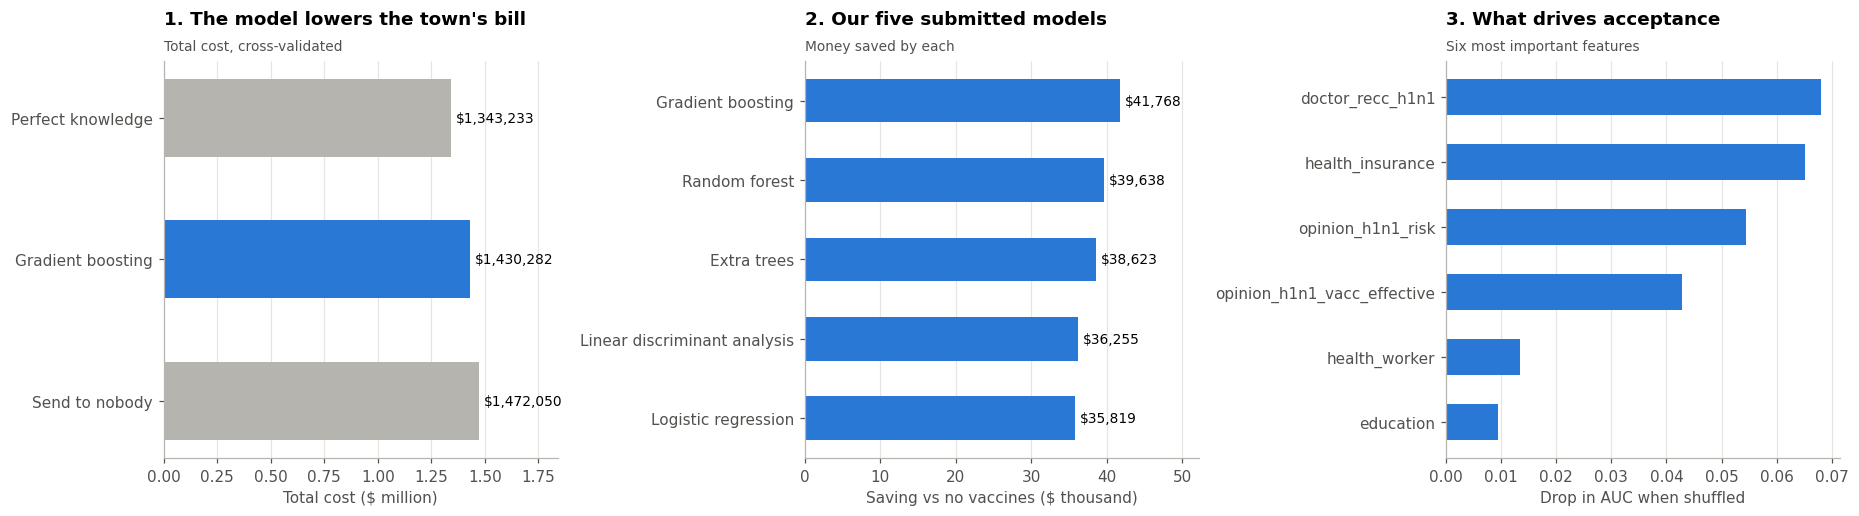

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Panel 1: best model against the reference points
compare = pd.Series({"Perfect knowledge": references["Perfect knowledge"],
                     winner["strategy"]: winner["cost"],
                     "Send to nobody": references["Send to nobody"]}).iloc[::-1]
bars = axes[0].barh(compare.index, compare.values / 1e6,
                    color=[GREY, BLUE, GREY], height=0.55)
axes[0].bar_label(bars, labels=[money(v) for v in compare.values], padding=3, fontsize=9)
axes[0].set_xlim(0, compare.max() / 1e6 * 1.25)
axes[0].set_xlabel("Total cost ($ million)")
axes[0].grid(False, axis="y")
headline(axes[0], "1. The model lowers the town's bill", "Total cost, cross-validated")

# Panel 2: the five submitted models
top5 = final.head(5).iloc[::-1]
bars = axes[1].barh(top5["strategy"], top5["saving"] / 1e3, color=BLUE, height=0.55)
axes[1].bar_label(bars, labels=[money(v) for v in top5["saving"]], padding=3, fontsize=9)
axes[1].set_xlim(0, top5["saving"].max() / 1e3 * 1.25)
axes[1].set_xlabel("Saving vs no vaccines ($ thousand)")
axes[1].grid(False, axis="y")
headline(axes[1], "2. Our five submitted models", "Money saved by each")

# Panel 3: what drives acceptance
top6 = top.tail(6)
axes[2].barh(top6.index, top6.values, color=BLUE, height=0.55)
axes[2].set_xlabel("Drop in AUC when shuffled")
axes[2].grid(False, axis="y")
headline(axes[2], "3. What drives acceptance", "Six most important features")

finish("summary_slide.png")

---
## 10. Summary
**What we did**
* Compared eight separate models on the town's total cost and submitted the best five.
* Built a cost model from published H1N1 figures and used it to set a personal
  cut-off for every respondent.

**What we found**
* The best model and its saving are printed in section 9; its predictions are in
  `challenge_submission_group_X_order_1.csv`.
* A wasted vaccine costs \$500, while an accepted one saves far less than that in
  expected hospital costs for a healthy adult. So vaccines go only to people very likely
  to accept, with a lower bar for people with chronic conditions.
* The cost rule clearly beats the usual 0.5 cut-off and beats sending no vaccines.
* The top models are close together, so their exact order may differ on the test set.
* Main drivers: a doctor's recommendation, health insurance, and opinions on H1N1 risk
  and vaccine effectiveness.

**Limitations**
* The hospitalisation risks come from published studies but are still estimates; the
  size of the age effect is our own assumption. Section 6.5 shows the conclusion holds
  across a wide range of risk levels.
* Costs are measured on the training data with cross-validation; the test set may differ.

**References**
* CDC. *Updated CDC Estimates of 2009 H1N1 Influenza Cases, Hospitalizations and Deaths
  in the United States, April 2009 - April 10, 2010.*
* Borse RH, et al. *Effects of Vaccine Program against Pandemic Influenza A(H1N1) Virus,
  United States, 2009-2010.* Emerging Infectious Diseases, 2013.
* Ward KA, Spokes PJ, McAnulty JM. *Case-Control Study of Risk Factors for
  Hospitalization Caused by Pandemic (H1N1) 2009.* Emerging Infectious Diseases, 2011.
* CDC. *2009 H1N1 Early Outbreak and Disease Characteristics.*